In [1]:
import pandas as pd
import tensorflow as tf
import numpy as np

2026-11-07 00:18:30.333712: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-07 00:18:30.386322: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:


org_df = pd.read_csv('fra.txt',sep='\t',header=None,
                 usecols=[0,1],
                 names=['English','French'])

In [3]:
org_df

,English,French
0,Go.,Va !
1,Go.,Marche.
2,Go.,En route !
3,Go.,Bouge !
4,Hi.,Salut !
...,...,...
240516,Death is something that we're often discourage...,La mort est une chose qu'on nous décourage sou...
240517,Since there are usually multiple websites on a...,Puisqu'il y a de multiples sites web sur chaqu...
240518,If someone who doesn't know your background sa...,Si quelqu'un qui ne connaît pas vos antécédent...
240519,It may be impossible to get a completely error...,Il est peut-être impossible d'obtenir un Corpu...


In [4]:
print(org_df.shape)
print(org_df.isnull().sum())

print(org_df.head())

(240521, 2)
English    0
French     0
dtype: int64
  English      French
0     Go.        Va !
1     Go.     Marche.
2     Go.  En route !
3     Go.     Bouge !
4     Hi.     Salut !


In [ ]:
#df  = org_df.iloc[:100000].copy()
df  = org_df.copy()


In [6]:
## Add start and end tokens
df['French'] = df['French'].apply(lambda x : '<sos> ' + x.strip() + ' <eos>')

'''
Original:
Bonjour mon ami.

After adding tokens:
<sos> Bonjour mon ami. <eos>

During inference, the decoder starts with <sos> and predicts subsequent words until it generates <eos>
'''

'\nOriginal:\nBonjour mon ami.\n\nAfter adding tokens:\n<sos> Bonjour mon ami. <eos>\n\nDuring inference, the decoder starts with <sos> and predicts subsequent words until it generates <eos>\n'

In [7]:
df

,English,French
0,Go.,<sos> Va ! <eos>
1,Go.,<sos> Marche. <eos>
2,Go.,<sos> En route ! <eos>
3,Go.,<sos> Bouge ! <eos>
4,Hi.,<sos> Salut ! <eos>
...,...,...
99995,Tom says that he can wait.,<sos> Tom dit qu'il peut attendre. <eos>
99996,Tom seemed to be doubtful.,<sos> Tom avait l'air douteux. <eos>
99997,Tom seemed very impressed.,<sos> Tom avait l'air très impressionné. <eos>
99998,Tom seems to be motivated.,<sos> Tom semble être motivé. <eos>


In [8]:
from tensorflow.keras.preprocessing.text import  Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

## Tokenizer test

In [9]:
sentences = [
    'I love deep learning.',
    'Deep learning is amazing!',
    'Do you love machine learning?'
]
tokenizer = Tokenizer(filters="")
#Fit the tokenizer on the text data to build the vocabulary
tokenizer.fit_on_texts(sentences)

word_index = tokenizer.word_index
print("Word Index Dictionary:")
print(word_index) 

#Convert sentences into sequences of integers
sequences = tokenizer.texts_to_sequences(sentences)
print("\nText to Sequences:")
print(sequences)

# Pad the sequences so they all have the same length for the neural network
padded_sequences = pad_sequences(sequences, padding='post', maxlen=5)
print("\nPadded Sequences:")
print(padded_sequences)

Word Index Dictionary:
{'love': 1, 'deep': 2, 'i': 3, 'learning.': 4, 'learning': 5, 'is': 6, 'amazing!': 7, 'do': 8, 'you': 9, 'machine': 10, 'learning?': 11}

Text to Sequences:
[[3, 1, 2, 4], [2, 5, 6, 7], [8, 9, 1, 10, 11]]

Padded Sequences:
[[ 3  1  2  4  0]
 [ 2  5  6  7  0]
 [ 8  9  1 10 11]]


In [10]:
eng_tokenizer = Tokenizer(filters="", oov_token="<OOV>") #filters="" means we don't want to filter out any characters, oov_token="<OOV>" means we want to use <OOV> for out-of-vocabulary words
fre_tokenizer = Tokenizer(filters="", oov_token="<OOV>") #filters="" means we don't want to filter out any characters, oov_token="<OOV>" means we want to use <OOV> for out-of-vocabulary words

In [11]:
eng_tokenizer.fit_on_texts(df['English'])
## Reads all the English sentence and builds a vocabulary

## I am happy , I am learning , I am fine. -> I am happy learning fine



eng_tokenizer.word_index # 0 is reserved for padding, so the index starts from 1

{'<OOV>': 1,
 'i': 2,
 'you': 3,
 'a': 4,
 'is': 5,
 'to': 6,
 'the': 7,
 'tom': 8,
 "i'm": 9,
 'do': 10,
 'it': 11,
 'was': 12,
 "don't": 13,
 'he': 14,
 'are': 15,
 'have': 16,
 'this': 17,
 'we': 18,
 'my': 19,
 'your': 20,
 "you're": 21,
 'that': 22,
 'you.': 23,
 'not': 24,
 'be': 25,
 "it's": 26,
 'of': 27,
 'what': 28,
 'did': 29,
 'can': 30,
 'like': 31,
 'in': 32,
 'they': 33,
 'me': 34,
 'it.': 35,
 'all': 36,
 'me.': 37,
 'for': 38,
 'want': 39,
 'very': 40,
 'know': 41,
 'she': 42,
 'how': 43,
 'no': 44,
 'on': 45,
 "that's": 46,
 "i'll": 47,
 "can't": 48,
 'that.': 49,
 'need': 50,
 'get': 51,
 'go': 52,
 'at': 53,
 "we're": 54,
 'just': 55,
 'why': 56,
 'were': 57,
 'got': 58,
 'has': 59,
 "didn't": 60,
 'with': 61,
 'tom.': 62,
 'think': 63,
 'here.': 64,
 'his': 65,
 'so': 66,
 'really': 67,
 'will': 68,
 "i've": 69,
 'one': 70,
 "isn't": 71,
 'see': 72,
 'who': 73,
 'this.': 74,
 'take': 75,
 'an': 76,
 "let's": 77,
 'had': 78,
 'good': 79,
 'where': 80,
 'come': 81,
 

In [12]:
## Converting text into numerical sequence

encoder_input = eng_tokenizer.texts_to_sequences(df['English'])

''' {
'i' : 1,
'am' : 2,
'learning' : 3
}

i am learning --> [1,2,3]
'''
encoder_input

[[114],
 [114],
 [114],
 [114],
 [2525],
 [2525],
 [3668],
 [3668],
 [3668],
 [3668],
 [3668],
 [3668],
 [3668],
 [912],
 [912],
 [912],
 [912],
 [912],
 [912],
 [912],
 [3669],
 [3670],
 [3670],
 [3670],
 [5994],
 [5994],
 [5994],
 [5105],
 [5106],
 [5106],
 [2164],
 [2164],
 [5995],
 [2401],
 [3671],
 [3671],
 [3671],
 [5107],
 [5107],
 [5107],
 [530],
 [530],
 [530],
 [530],
 [2276],
 [2276],
 [52, 269],
 [52, 269],
 [52, 269],
 [7272],
 [7272],
 [3088],
 [3088],
 [3088],
 [3088],
 [2, 1260],
 [2, 1260],
 [2, 539],
 [2, 5108],
 [2, 5108],
 [2, 861],
 [5109, 7273],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [1133],
 [5110],
 [5110],
 [1134],
 [1134],
 [1134],
 [9756],
 [5996],
 [5996],
 [5996],
 [203, 35],
 [203, 35],
 [203, 35],
 [203, 35],
 [5111],
 [5111],
 [5111],
 [5111],
 [148, 35],
 [148, 35],
 [9757],
 [51, 111],
 [51, 111],
 [51, 111],
 [52, 90],
 [52, 90],
 [52, 90],
 [58, 672],
 [58, 672],
 [58, 672],
 [58, 96],
 [58

In [13]:
fre_tokenizer.fit_on_texts(df['French'])

In [14]:
decoder_input = fre_tokenizer.texts_to_sequences(
    df['French']
)

In [15]:
max_len_eng = max(len(x) for x in encoder_input)
max_len_fre = max(len(x) for x in decoder_input)
## Finding the longest sentence in each language
'''
sen1 = [1,2,3]  -->length = 3
sen2 = [4,5]     -->length = 2
sen3 = [6,7,8,9] -->length = 4
max_len = 4
'''
print(max_len_eng, max_len_fre)

8 16


In [16]:
# Padding to make same length sequences
from tensorflow.keras.preprocessing.sequence import pad_sequences
'''
sen1 = [1,2,3]  to [1,2,3,0]
sen2 = [4,5]     to [4,5,0,0]
sen3 = [6,7,8,9] to [6,7,8,9]
'''
encoder_input = pad_sequences(encoder_input,max_len_eng,padding='post') # zeros at the end

decoder_input = pad_sequences(decoder_input,max_len_fre,padding='post') # zeros at the end

encoder_input



array([[114,   0,   0, ...,   0,   0,   0],
       [114,   0,   0, ...,   0,   0,   0],
       [114,   0,   0, ...,   0,   0,   0],
       ...,
       [  8, 619,  40, ...,   0,   0,   0],
       [  8, 231,   6, ...,   0,   0,   0],
       [  8, 231,   6, ...,   0,   0,   0]], dtype=int32)

In [17]:
decoder_target = [] # create an empty list to store the target sequence


''' e.g. decoder is ecpected to predict je suis heureux <eos>, This is called teacher forcing during training.
<sos> je suis heureux <eos>
decoder_input = [1, 2, 3, 4, 5]
decoder_target = [2, 3, 4, 5]
'''


for seq in decoder_input:
    decoder_target.append(seq[1:])  # keep everything except <sos>

decoder_target = pad_sequences(
    decoder_target,
    maxlen=max_len_fre,
    padding='post'
)
    
decoder_target    

'''here is one additional consideration: padded target positions should not contribute to the loss function.
We will handle that during training.'''
    

'here is one additional consideration: padded target positions should not contribute to the loss function.\nWe will handle that during training.'

In [18]:
# Calculate vocabulary length
eng_vocab_size = len(eng_tokenizer.word_index) + 1
fre_vocab_size = len(fre_tokenizer.word_index) + 1

'''
Why do we add 1?

Because index 0 is reserved for padding.
0 → Padding
1 → I
2 → am
3 → happy

'''
print(eng_vocab_size, fre_vocab_size)
#These vocabulary sizes will determine the dimensions of the embedding and output layers.

14607 27315


In [19]:
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

In [20]:
# Embedding -> vector representation of words
'''
I am learning -> [1,2,3] -> [[0.1,0.2,0.3],[0.4,0.5,0.6],[0.7,0.8,0.9]]  (3 words, each represented by a 3-dimensional vector)
'''
encoder_inputs =Input(shape=(max_len_eng,),
                      name = 'encoder_input_layer')

enc_emb = Embedding(
    eng_vocab_size,
    512,
    mask_zero=True, # the LSTM can ignore padded input positions.,
    name = 'encoder_embedding_layer'
    
)(encoder_inputs)

enc_emb.shape

I0000 00:00:1793990917.441738   29929 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14259 MB memory:  -> device: 0, name: NVIDIA RTX A4000, pci bus id: 0000:31:00.0, compute capability: 8.6
I0000 00:00:1793990917.443527   29929 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 14260 MB memory:  -> device: 1, name: NVIDIA RTX A4000, pci bus id: 0000:4b:00.0, compute capability: 8.6


(None, 8, 512)

Suppose
- Batch size = 100
- Maximum English sentence length = 10
- Embedding dimension = 512
The encoder input has shape:
\[
(100,10)
\]

After embedding:
\[
(100,10,512)
\]

What does this mean?

Each word is converted into a 512-dimensional vector.

For example

I       → [0.21, 0.32, ..., 0.15] \
am      → [0.13, 0.42, ..., 0.27] \
happy   → [0.54, 0.19, ..., 0.31] 

In [21]:
# create the LSTM

from keras.src.layers import LSTM


enc_lstm = LSTM(512, return_state=True, # return_state=True means we want to get the hidden and cell states of the LSTM
                name = 'encoder_lstm_layer')

'''
# Does it need to have the same dim as the embedding layer? 
Yes, because the LSTM will take the embedding as input, so the input dimension of the LSTM 
should match the output dimension of the embedding layer. In this case, both are 512. 
'''

'\n# Does it need to have the same dim as the embedding layer? \nYes, because the LSTM will take the embedding as input, so the input dimension of the LSTM \nshould match the output dimension of the embedding layer. In this case, both are 512. \n'

In [22]:
encoder_output, state_h,state_c = enc_lstm(enc_emb)

# create the context vector by concatenating the hidden and cell states
encoder_states = [state_h, state_c]

encoder_output.shape

(None, 512)

In [ ]:
# Decoder Architecture
decoder_inputs = Input(shape=(max_len_fre,),
                       name = 'decoder_input_layer')

dec_emb = Embedding(
    fre_vocab_size,
    512,
    mask_zero=True,
    name = 'decoder_embedding_layer'
)(decoder_inputs)
dec_emb


<KerasTensor shape=(None, 16, 512), dtype=float32, sparse=False, ragged=False, name=keras_tensor_5>

In [ ]:
# Decoder LSTM
from keras.layers import LSTM


dec_lstm = LSTM(512, 
                return_sequences=True, # Returns the output at every time step
                return_state=True, #Returns the final hidden and cell states,
                name = 'decoder_lstm_layer'
)

In [25]:
decoder_output, _, _ = dec_lstm(
    dec_emb,
    initial_state=encoder_states # Initialize the decoder LSTM with the encoder's final hidden and cell states
)
decoder_output.shape

(None, 16, 512)

In [26]:
# Dense layer to generate predictions for each time step with softmax
decoder_dense = Dense(
    fre_vocab_size, 
    activation = 'softmax'
)
decoder_probability_output = decoder_dense(decoder_output) # passed the decoder output to the dense layer to get the probability distribution over the French vocabulary for each time step
decoder_probability_output.shape

(None, 16, 27315)

In [27]:
# Complete model
model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_probability_output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input_layer │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input_layer │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding_… │ (None, 8, 512)    │  7,478,784 │ encoder_input_la… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 8)         │          0 │ encoder_input_la… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding_… │ (None, 16, 512)   │ 13,985,280 │ decoder_input_la… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm_layer  │ [(None, 512),     │  2,099,200 │ encoder_embeddin… │
│ (LSTM)              │ (None, 512),      │            │ not_equal[0][0]   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm_layer  │ [(None, 16, 512), │  2,099,200 │ decoder_embeddin… │
│ (LSTM)              │ (None, 512),      │            │ encoder_lstm_lay… │
│                     │ (None, 512)]      │            │ encoder_lstm_lay… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16, 27315) │ 14,012,595 │ decoder_lstm_lay… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 39,675,059 (151.35 MB)

 Trainable params: 39,675,059 (151.35 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model.compile(
    optimizer='adam', # updates the 
    loss='sparse_categorical_crossentropy', # sparse_categorical_crossentropy is used when the target labels are integers (not one-hot encoded)
    metrics=['accuracy']
)

In [29]:
encoder_input_data = encoder_input
decoder_input_data = decoder_input
decoder_target_data = decoder_target

sample_weights = (
    decoder_target_data != 0
).astype('float32')

print("Encoder input:", encoder_input_data.shape)
print("Decoder input:", decoder_input_data.shape)
print("Decoder target:", decoder_target_data.shape)
print("Sample weights:", sample_weights.shape)

Encoder input: (100000, 8)
Decoder input: (100000, 16)
Decoder target: (100000, 16)
Sample weights: (100000, 16)


In [30]:
print("Model output:", model.output_shape)
print("French vocabulary:", fre_vocab_size)
print("Target shape:", decoder_target_data.shape)

Model output: (None, 16, 27315)
French vocabulary: 27315
Target shape: (100000, 16)


In [31]:
epochs = 20
history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=32, # 10000/32 FOR LARGE MODELS PEOPLE USE 8
    epochs=20,
    validation_split=0.2
)

Epoch 1/20


2026-11-07 00:18:42.580054: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91700


2500/2500 ━━━━━━━━━━━━━━━━━━━━ 197s 77ms/step - accuracy: 0.4990 - loss: 3.3889 - val_accuracy: 0.5362 - val_loss: 2.9574
Epoch 2/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 195s 78ms/step - accuracy: 0.6600 - loss: 1.8488 - val_accuracy: 0.6064 - val_loss: 2.4730
Epoch 3/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 192s 77ms/step - accuracy: 0.7472 - loss: 1.1460 - val_accuracy: 0.6312 - val_loss: 2.3582
Epoch 4/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 191s 76ms/step - accuracy: 0.8062 - loss: 0.7589 - val_accuracy: 0.6414 - val_loss: 2.3722
Epoch 5/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 194s 77ms/step - accuracy: 0.8475 - loss: 0.5491 - val_accuracy: 0.6449 - val_loss: 2.4284
Epoch 6/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 193s 77ms/step - accuracy: 0.8726 - loss: 0.4386 - val_accuracy: 0.6463 - val_loss: 2.4891
Epoch 7/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 195s 78ms/step - accuracy: 0.8879 - loss: 0.3765 - val_accuracy: 0.6482 - val_loss: 2.5313
Epoch 8/20
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 190s 76ms/step - accuracy: 0.8968 - lo

In [32]:
train_accuracy = history.history['accuracy'][-1]
validation_accuracy = history.history['val_accuracy'][-1]
train_accuracy, validation_accuracy

(0.9177542924880981, 0.6505459547042847)

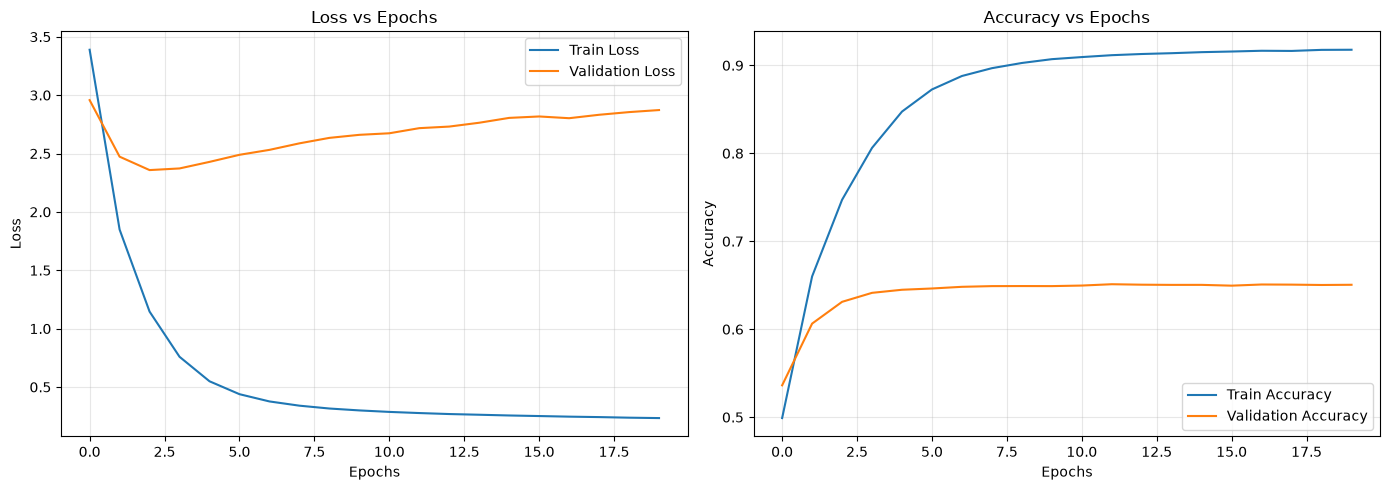

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_title('Loss vs Epochs')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_title('Accuracy vs Epochs')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
#Dictionary comprehension to create a mapping from index to word for English vocabulary 
eng_index_word = {
    v : k for k, v in eng_tokenizer.word_index.items() # reverse the key-value pairs in the word_index dictionary to create a mapping from index to word
}

fre_index_word = {
    v : k for k, v in fre_tokenizer.word_index.items() # reverse the key-value pairs in the word_index dictionary to create a mapping from index to word
}
eng_index_word

{1: '<OOV>',
 2: 'i',
 3: 'you',
 4: 'a',
 5: 'is',
 6: 'to',
 7: 'the',
 8: 'tom',
 9: "i'm",
 10: 'do',
 11: 'it',
 12: 'was',
 13: "don't",
 14: 'he',
 15: 'are',
 16: 'have',
 17: 'this',
 18: 'we',
 19: 'my',
 20: 'your',
 21: "you're",
 22: 'that',
 23: 'you.',
 24: 'not',
 25: 'be',
 26: "it's",
 27: 'of',
 28: 'what',
 29: 'did',
 30: 'can',
 31: 'like',
 32: 'in',
 33: 'they',
 34: 'me',
 35: 'it.',
 36: 'all',
 37: 'me.',
 38: 'for',
 39: 'want',
 40: 'very',
 41: 'know',
 42: 'she',
 43: 'how',
 44: 'no',
 45: 'on',
 46: "that's",
 47: "i'll",
 48: "can't",
 49: 'that.',
 50: 'need',
 51: 'get',
 52: 'go',
 53: 'at',
 54: "we're",
 55: 'just',
 56: 'why',
 57: 'were',
 58: 'got',
 59: 'has',
 60: "didn't",
 61: 'with',
 62: 'tom.',
 63: 'think',
 64: 'here.',
 65: 'his',
 66: 'so',
 67: 'really',
 68: 'will',
 69: "i've",
 70: 'one',
 71: "isn't",
 72: 'see',
 73: 'who',
 74: 'this.',
 75: 'take',
 76: 'an',
 77: "let's",
 78: 'had',
 79: 'good',
 80: 'where',
 81: 'come',
 

In [35]:
fre_tokenizer.word_index

{'<OOV>': 1,
 '<sos>': 2,
 '<eos>': 3,
 'je': 4,
 'pas': 5,
 '?': 6,
 'de': 7,
 'ne': 8,
 'tom': 9,
 'le': 10,
 'vous': 11,
 'que': 12,
 'est': 13,
 'il': 14,
 'à': 15,
 'la': 16,
 'nous': 17,
 'un': 18,
 'tu': 19,
 'a': 20,
 'suis': 21,
 "c'est": 22,
 "j'ai": 23,
 '!': 24,
 'ce': 25,
 'en': 26,
 'une': 27,
 'me': 28,
 'les': 29,
 'ça': 30,
 'tout': 31,
 'te': 32,
 'elle': 33,
 'mon': 34,
 'qui': 35,
 'sont': 36,
 'fait': 37,
 "n'est": 38,
 'très': 39,
 'pour': 40,
 'des': 41,
 'est-ce': 42,
 'faire': 43,
 'ils': 44,
 'êtes': 45,
 'du': 46,
 'se': 47,
 'tom.': 48,
 'veux': 49,
 'peux': 50,
 'sommes': 51,
 'été': 52,
 'es': 53,
 'ça.': 54,
 'y': 55,
 'votre': 56,
 'dans': 57,
 'pourquoi': 58,
 'pas.': 59,
 'ma': 60,
 'plus': 61,
 'besoin': 62,
 'sais': 63,
 'était': 64,
 'avec': 65,
 'comment': 66,
 'où': 67,
 'elles': 68,
 'au': 69,
 'cela': 70,
 'ton': 71,
 'être': 72,
 'si': 73,
 'cette': 74,
 'on': 75,
 "n'ai": 76,
 "l'air": 77,
 'personne': 78,
 'êtes-vous': 79,
 'vraiment': 80,
 '

In [36]:
# translation
def translate_Sentence(sentence):
    ## step1 -> convert english sentence into neumerical values
    seq = eng_tokenizer.texts_to_sequences([sentence])
    
    # Step 2: Check whether words were recognized
    if len(seq[0]) == 0:
        return "Input sentence contains no known English words."
    
    ## step3 -> apply padding
    seq = pad_sequences(seq,
                        maxlen=max_len_eng,
                        padding='post'
                        )
    ## Step4 -> Get the start and end token ids
    start_token = fre_tokenizer.word_index['<sos>']
    end_token = fre_tokenizer.word_index['<eos>']
    
    ## Step5 -> start decoder with <sos>
    decoder_sequence = [start_token]
    
    translated_sentence = []
    
    ##step5 -> predict one word at a time
    for i in range(max_len_fre -1): # -1 because the start token <sos> is already in the decoder_sequence
        decoder_input = pad_sequences([decoder_sequence],
                                        maxlen=max_len_fre,
                                        padding='post'
                                        )
        prediction = model.predict(
            [seq,decoder_input],
            verbose=0
        )
        
        ## Get the word ID with the highest probability
        
        next_word_id = np.argmax(prediction[0, len(decoder_sequence)-1, :])
        
        ## stop if the end token is predicted or padding token is predicted
        if next_word_id == end_token or next_word_id == 0:
            break
        
        ## Convert the neumerical id to french word
        translated_word = fre_index_word[next_word_id]
        translated_sentence.append(translated_word)
        
        ## add the predicted word to the decoder input for the next iteration
        decoder_sequence.append(next_word_id)
        
    return ' '.join(translated_sentence)      

In [40]:
sentence = "I am happy."
translated_sentence = translate_Sentence(sentence)
print(f"English: {sentence}")
print(f"French: {translated_sentence}")

English: I am happy.
French: je suis heureuse.


In [41]:
test_sentences = [
    "Good Morning.",
    "I love you",
    "How are you?",
    "I am learning.",
    "Thank you."
]

for sentence in test_sentences:
    print(f"English: {sentence}")
    print(f"French: {translate_Sentence(sentence)}")
    print("-" * 40)

English: Good Morning.
French: bonjour.
----------------------------------------
English: I love you
French: je t'aime ?
----------------------------------------
English: How are you?
French: ça va ?
----------------------------------------
English: I am learning.
French: je comprends.
----------------------------------------
English: Thank you.
French: je te remercie.
----------------------------------------
